### Gastric cancer

In [ ]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.model_selection import StratifiedGroupKFold

##### Fsocre

In [3]:
# 加载数据集
file_path = '../Fscore/Gastric_sample_FscoreSorted_selected20.csv'
Fscoredata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Fscore(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Fscore/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [6]:
Gastric_leaderboard_Fscore = prepare_train_test_Fscore(Fscoredata, "Gastric cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       188.57 GB / 251.54 GB (75.0%)
Disk Space Avail:   8944.01 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [7]:
Gastric_leaderboard_Fscore.to_csv("Gastric_leaderboard_Fscore.csv", index=False)
Gastric_leaderboard_Fscore

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.975000,0.924051,0.923397,0.852276,0.918919,0.971429,0.871795,0.975000,0.959538,roc_auc,0.057143,0.101133,1.440916,0.057143,0.101133,1.440916,1,True,2
1,WeightedEnsemble_L2,0.973718,0.911392,0.910577,0.829165,0.904110,0.970588,0.846154,0.973718,0.962845,roc_auc,2.322508,0.245836,8.385118,0.002066,0.000491,0.028780,2,True,5
2,LightGBM_BAG_L1,0.969872,0.924051,0.923397,0.852276,0.918919,0.971429,0.871795,0.969872,0.955577,roc_auc,0.222976,0.006573,0.451192,0.222976,0.006573,0.451192,1,True,1
3,XGBoost_BAG_L1,0.969872,0.936709,0.936218,0.875811,0.933333,0.972222,0.897436,0.969872,0.951637,roc_auc,0.295122,0.022226,0.517141,0.295122,0.022226,0.517141,1,True,4
4,NeuralNetFastAI_BAG_L1,0.956410,0.873418,0.872756,0.750338,0.864865,0.914286,0.820513,0.956410,0.946227,roc_auc,1.968178,0.121987,6.398280,1.968178,0.121987,6.398280,1,True,3


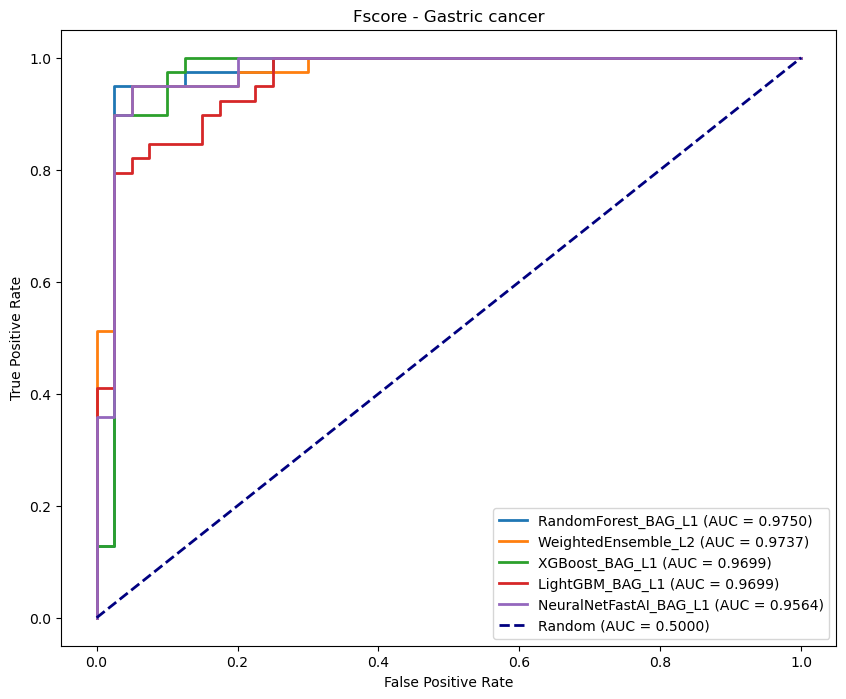

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Fscore(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Fscore - Gastric cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/Fscore'
data = Fscoredata 
plot_roc_curves_Fscore(data, model_dir)


##### ANOVA

In [6]:
# 加载数据集
file_path = '../ANOVA/Gastric_sample_AnovaSorted_selected20.csv'
ANOVAdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ANOVA(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ANOVA/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [11]:
Gastric_leaderboard_ANOVA = prepare_train_test_ANOVA(ANOVAdata, "Gastric cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.68 GB / 251.54 GB (74.6%)
Disk Space Avail:   8944.01 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [12]:
Gastric_leaderboard_ANOVA.to_csv("Gastric_leaderboard_ANOVA.csv", index=False)
Gastric_leaderboard_ANOVA

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.975000,0.924051,0.923397,0.852276,0.918919,0.971429,0.871795,0.975000,0.959538,roc_auc,0.050539,0.100803,1.262684,0.050539,0.100803,1.262684,1,True,2
1,WeightedEnsemble_L2,0.973718,0.911392,0.910577,0.829165,0.904110,0.970588,0.846154,0.973718,0.962845,roc_auc,1.164932,0.273840,8.956890,0.002028,0.000450,0.023062,2,True,5
2,LightGBM_BAG_L1,0.969872,0.924051,0.923397,0.852276,0.918919,0.971429,0.871795,0.969872,0.955577,roc_auc,0.139861,0.007015,0.490115,0.139861,0.007015,0.490115,1,True,1
3,XGBoost_BAG_L1,0.969872,0.936709,0.936218,0.875811,0.933333,0.972222,0.897436,0.969872,0.951637,roc_auc,0.262926,0.020364,0.463105,0.262926,0.020364,0.463105,1,True,4
4,NeuralNetFastAI_BAG_L1,0.956410,0.873418,0.872756,0.750338,0.864865,0.914286,0.820513,0.956410,0.946227,roc_auc,0.849440,0.152222,7.208039,0.849440,0.152222,7.208039,1,True,3


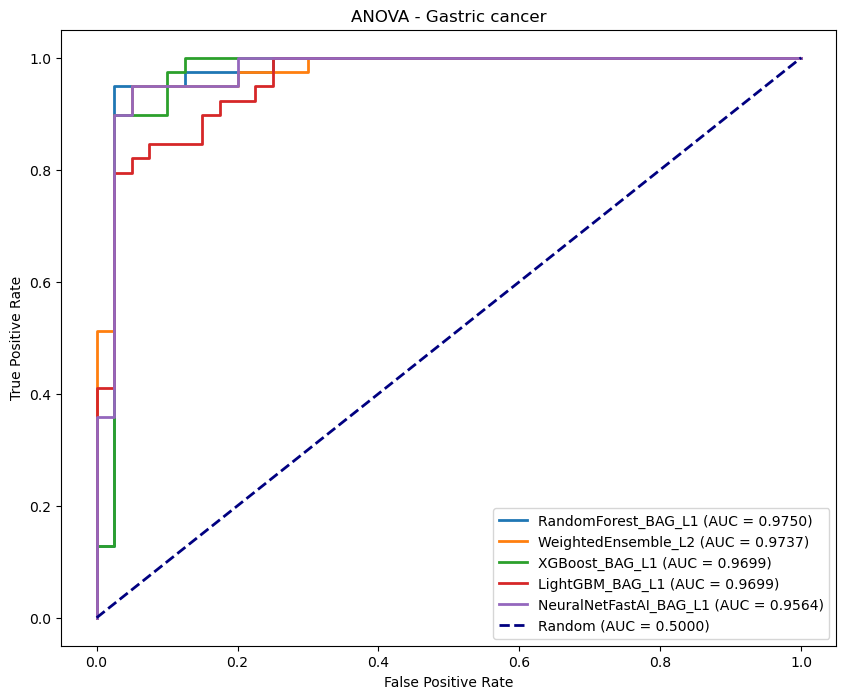

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ANOVA(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ANOVA - Gastric cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/ANOVA'
data = ANOVAdata 
plot_roc_curves_ANOVA(data, model_dir)


##### ReliefF

In [12]:
# 加载数据集
file_path = '../ReliefF/Gastric_sample_ReliefFSorted_selected27.csv'
ReliefFdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ReliefF(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ReliefF/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [16]:
Gastric_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "Gastric cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.51 GB / 251.54 GB (74.5%)
Disk Space Avail:   8944.01 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

Leaderboard on holdout data (DyStack):
                      model  score_holdout  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0       RandomForest_BAG_L1            1.0   0.970317     roc_auc        0.041420       0.101521   1.769550                 0.041420                0.101521           1.769550            1       True          2
1            XGBoost_BAG_L1            1.0   0.964572     roc_auc        0.283172       0.023329   0.504446                 0.283172                0.023329           0.504446            1       True          4
2           LightGBM_BAG_L1            1.0   0.959371     roc_auc        0.317691       0.006941   0.493542                 0.317691                0.006941           0.493542            1       True          1
3    NeuralNetFastAI_BAG_L1            1.0   0.973086     roc_auc        2.266952       0.219938  12.584348          

In [17]:
Gastric_leaderboard_ReliefF.to_csv("Gastric_leaderboard_ReliefF.csv", index=False)
Gastric_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.978205,0.936709,0.936218,0.875811,0.933333,0.972222,0.897436,0.978205,0.977870,roc_auc,1.196171,0.328705,11.265131,0.002256,0.000499,0.022751,2,True,5
1,RandomForest_BAG_L1,0.970192,0.911392,0.910897,0.824974,0.906667,0.944444,0.871795,0.970192,0.972073,roc_auc,0.058744,0.102391,1.251389,0.058744,0.102391,1.251389,1,True,2
2,NeuralNetFastAI_BAG_L1,0.968590,0.898734,0.898397,0.798332,0.894737,0.918919,0.871795,0.968590,0.970684,roc_auc,0.750332,0.196602,9.027757,0.750332,0.196602,9.027757,1,True,3
3,LightGBM_BAG_L1,0.967949,0.911392,0.911218,0.822964,0.909091,0.921053,0.897436,0.967949,0.970970,roc_auc,0.147799,0.006833,0.492648,0.147799,0.006833,0.492648,1,True,1
4,XGBoost_BAG_L1,0.957051,0.911392,0.911218,0.822964,0.909091,0.921053,0.897436,0.957051,0.973747,roc_auc,0.237040,0.022380,0.470586,0.237040,0.022380,0.470586,1,True,4


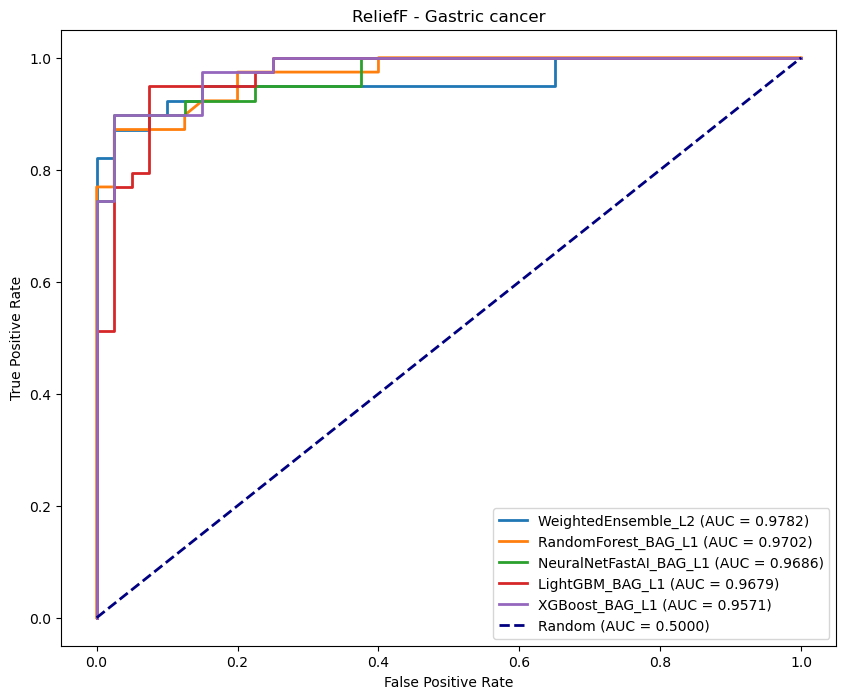

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ReliefF(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ReliefF - Gastric cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/ReliefF'
data = ReliefFdata 
plot_roc_curves_ReliefF(data, model_dir)


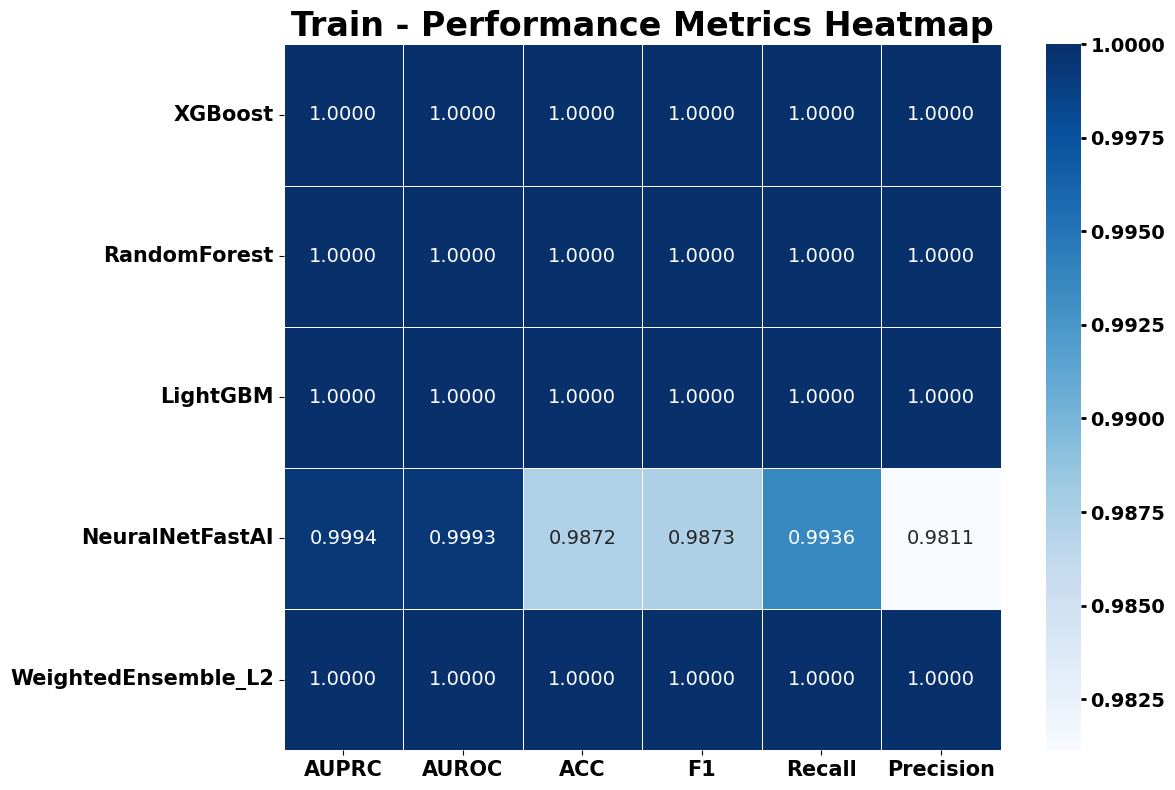

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score, recall_score, precision_score
from sklearn.model_selection import train_test_split
from autogluon.tabular import TabularPredictor

def plot_model_performance_heatmap(data, model_dir):
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1',
              'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    model_name_map = {m: m.replace('_BAG_L1', '') for m in models}

    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    results = []

    for model_name in models:
        try:
            y_true = train_data['class']
            y_proba = predictor.predict_proba(train_data, model=model_name)
            y_score = y_proba.iloc[:, 1] if isinstance(y_proba, pd.DataFrame) else y_proba
            y_pred = predictor.predict(train_data, model=model_name)

            auc = roc_auc_score(y_true, y_score)
            auprc = average_precision_score(y_true, y_score)
            acc = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            recall = recall_score(y_true, y_pred)
            precision = precision_score(y_true, y_pred)

            results.append([model_name_map[model_name], auprc, auc, acc, f1, recall, precision])
        except Exception as e:
            print(f"{model_name} failed: {e}")
            results.append([model_name_map[model_name]] + [np.nan]*6)

    df = pd.DataFrame(results, columns=['Model', 'AUPRC', 'AUROC', 'ACC', 'F1', 'Recall', 'Precision'])
    df.set_index('Model', inplace=True)

    plt.figure(figsize=(12, 8))
    sns.heatmap(df, annot=True, cmap='Blues', fmt=".4f", linewidths=0.5, annot_kws={"size": 14})
    cbar = plt.gca().collections[0].colorbar
    cbar.ax.tick_params(labelsize=14, width=2)  # 加粗刻度线
    for tick_label in cbar.ax.get_yticklabels():
        tick_label.set_fontweight('bold')       # 加粗字体

    plt.title("Train - Performance Metrics Heatmap", fontsize=24, fontweight='bold')
    plt.ylabel("")  # 去除纵轴标签
    plt.xticks(fontsize=15, fontweight='bold')
    plt.yticks(fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{model_dir}/model_performance_heatmap_train.png", dpi=300)
    plt.show()

# 调用
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/ReliefF'
data = ReliefFdata 
plot_model_performance_heatmap(data, model_dir)

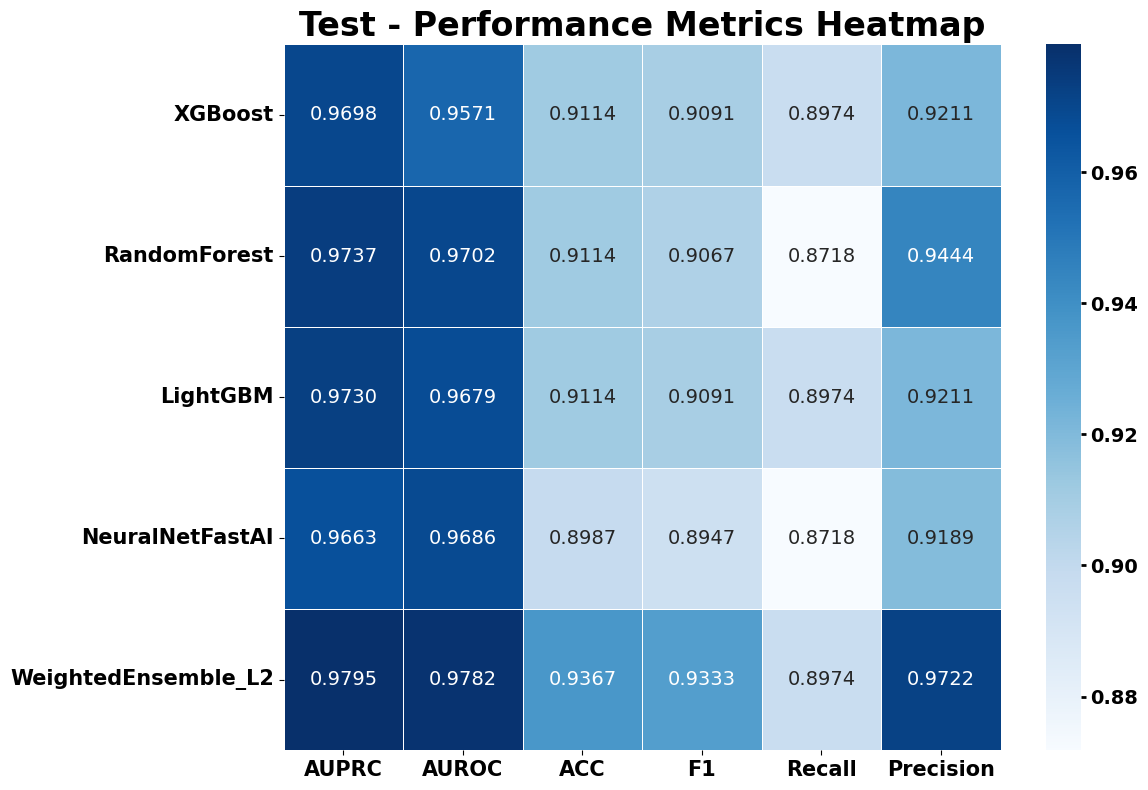

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score, recall_score, precision_score
from sklearn.model_selection import train_test_split
from autogluon.tabular import TabularPredictor

def plot_model_performance_heatmap(data, model_dir):
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1',
              'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    model_name_map = {m: m.replace('_BAG_L1', '') for m in models}

    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    results = []

    for model_name in models:
        try:
            y_true = test_data['class']
            y_proba = predictor.predict_proba(test_data, model=model_name)
            y_score = y_proba.iloc[:, 1] if isinstance(y_proba, pd.DataFrame) else y_proba
            y_pred = predictor.predict(test_data, model=model_name)

            auc = roc_auc_score(y_true, y_score)
            auprc = average_precision_score(y_true, y_score)
            acc = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            recall = recall_score(y_true, y_pred)
            precision = precision_score(y_true, y_pred)

            results.append([model_name_map[model_name], auprc, auc, acc, f1, recall, precision])
        except Exception as e:
            print(f"{model_name} failed: {e}")
            results.append([model_name_map[model_name]] + [np.nan]*6)

    df = pd.DataFrame(results, columns=['Model', 'AUPRC', 'AUROC', 'ACC', 'F1', 'Recall', 'Precision'])
    df.set_index('Model', inplace=True)

    plt.figure(figsize=(12, 8))
    sns.heatmap(df, annot=True, cmap='Blues', fmt=".4f", linewidths=0.5, annot_kws={"size": 14})
    cbar = plt.gca().collections[0].colorbar
    cbar.ax.tick_params(labelsize=14, width=2)  # 加粗刻度线
    for tick_label in cbar.ax.get_yticklabels():
        tick_label.set_fontweight('bold')       # 加粗字体

    plt.title("Test - Performance Metrics Heatmap", fontsize=24, fontweight='bold')
    plt.ylabel("")  # 去除纵轴标签
    plt.xticks(fontsize=15, fontweight='bold')
    plt.yticks(fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{model_dir}/model_performance_heatmap_test.png", dpi=300)
    plt.show()

# 调用
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/ReliefF'
data = ReliefFdata 
plot_model_performance_heatmap(data, model_dir)

In [22]:
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, precision_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 重新加载模型和数据
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/ReliefF'
predictor = TabularPredictor.load(model_dir)
data = ReliefFdata

# 模型名称列表
models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

# 数据划分
train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

# 用于保存结果
results = []

# 遍历每个模型并计算各项指标
for model_name in models:
    model = predictor._trainer.load_model(model_name)
    
    for set_name, df in [('Train', train_data), ('Test', test_data)]:
        y_true = df['class']
        y_proba = model.predict_proba(df)
        if isinstance(y_proba, pd.DataFrame):
            y_score = y_proba.iloc[:, 1]
        else:
            y_score = y_proba
        y_pred = (y_score >= 0.5).astype(int)

        results.append({
            'Model': model_name,
            'Set': set_name,
            'AUC': roc_auc_score(y_true, y_score),
            'Accuracy': accuracy_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred)
        })

# 转换为 DataFrame 展示
results_df = pd.DataFrame(results)
# 按 Test AUC 排序，仅保留 Test 行并根据 AUC 降序排列后提取顺序索引
test_auc_order = results_df[results_df['Set'] == 'Test'].sort_values(by='AUC', ascending=False)['Model']

# 按上述顺序重新排列整个结果 DataFrame（Validation 和 Test 行都保持）
results_df['Model'] = pd.Categorical(results_df['Model'], categories=test_auc_order, ordered=True)
results_df = results_df.sort_values(by=['Model', 'Set']).reset_index(drop=True)
results_df

,Model,Set,AUC,Accuracy,F1,Recall,Precision
0,WeightedEnsemble_L2,Test,0.978205,0.936709,0.933333,0.897436,0.972222
1,WeightedEnsemble_L2,Train,1.000000,1.000000,1.000000,1.000000,1.000000
2,RandomForest_BAG_L1,Test,0.970192,0.911392,0.906667,0.871795,0.944444
3,RandomForest_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
4,NeuralNetFastAI_BAG_L1,Test,0.968590,0.898734,0.894737,0.871795,0.918919
5,NeuralNetFastAI_BAG_L1,Train,0.999347,0.987220,0.987342,0.993631,0.981132
6,LightGBM_BAG_L1,Test,0.967949,0.911392,0.909091,0.897436,0.921053
7,LightGBM_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
8,XGBoost_BAG_L1,Test,0.957051,0.911392,0.909091,0.897436,0.921053
9,XGBoost_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000


### Binomial

In [17]:
# 加载数据集
file_path = '../Binomial/Gastric_sample_BinomialSorted_selected74.csv'
Binomialdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Binomial(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Binomial/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [23]:
Gastric_leaderboard_Binomial = prepare_train_test_Binomial(Binomialdata, "Gastric cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.68 GB / 251.54 GB (74.6%)
Disk Space Avail:   8944.01 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [24]:
Gastric_leaderboard_Binomial.to_csv("Gastric_leaderboard_Binomial.csv", index=False)
Gastric_leaderboard_Binomial

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L2,0.958974,0.860759,0.859295,0.740261,0.840580,0.966667,0.743590,0.958974,0.939000,roc_auc,2.031471,0.422297,15.289294,0.783360,0.153193,6.444669,2,True,8
1,XGBoost_BAG_L1,0.950000,0.936709,0.936538,0.873637,0.935065,0.947368,0.923077,0.950000,0.931774,roc_auc,0.285002,0.027382,0.938569,0.285002,0.027382,0.938569,1,True,4
2,LightGBM_BAG_L2,0.944872,0.898734,0.897756,0.806443,0.888889,0.969697,0.820513,0.944872,0.944349,roc_auc,1.395815,0.277462,9.382705,0.147704,0.008358,0.538081,2,True,6
3,WeightedEnsemble_L2,0.941667,0.911392,0.911218,0.822964,0.909091,0.921053,0.897436,0.941667,0.935897,roc_auc,1.200177,0.163380,7.575632,0.001965,0.000465,0.027875,2,True,5
4,WeightedEnsemble_L3,0.935256,0.898734,0.897756,0.806443,0.888889,0.969697,0.820513,0.935256,0.955863,roc_auc,2.287089,0.464847,16.128585,0.001693,0.000974,0.076439,3,True,11
5,LightGBM_BAG_L1,0.933974,0.898734,0.898718,0.797436,0.897436,0.897436,0.897436,0.933974,0.932672,roc_auc,0.172361,0.007665,0.578456,0.172361,0.007665,0.578456,1,True,1
6,WeightedEnsemble_BAG_L2,0.933974,0.886076,0.885897,0.772290,0.883117,0.894737,0.871795,0.933974,0.928344,roc_auc,1.254524,0.277301,8.941728,0.006413,0.008197,0.097104,2,True,10
7,XGBoost_BAG_L2,0.920513,0.898734,0.897756,0.806443,0.888889,0.969697,0.820513,0.920513,0.946758,roc_auc,1.502037,0.310680,9.607476,0.253926,0.041577,0.762852,2,True,9
8,RandomForest_BAG_L2,0.907372,0.873418,0.872115,0.762024,0.857143,0.967742,0.769231,0.907372,0.937224,roc_auc,1.288037,0.370265,10.019966,0.039925,0.101162,1.175341,2,True,7
9,RandomForest_BAG_L1,0.898397,0.848101,0.847756,0.696854,0.842105,0.864865,0.820513,0.898397,0.925527,roc_auc,0.049900,0.106189,1.296868,0.049900,0.106189,1.296868,1,True,2


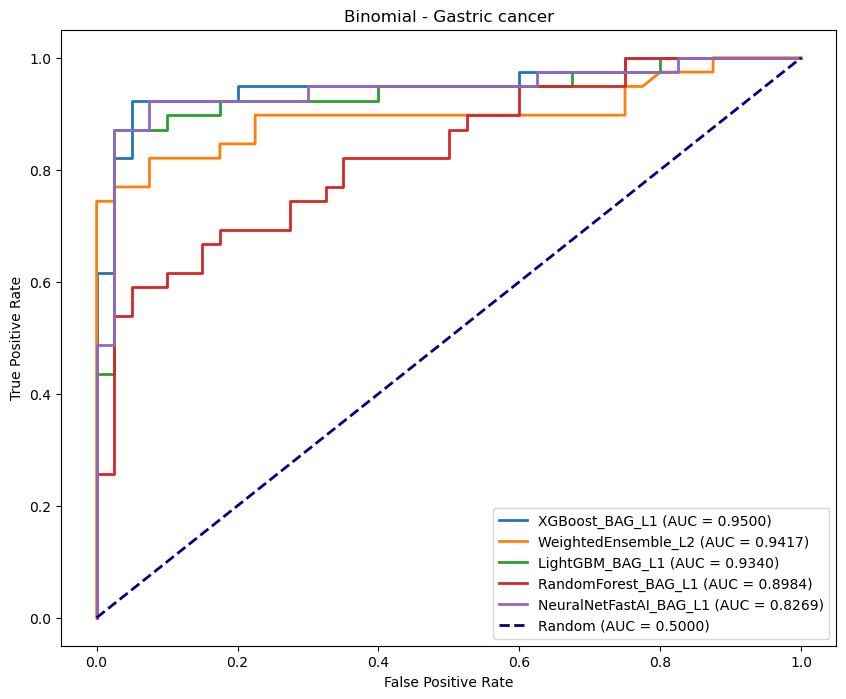

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Binomial(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Binomial - Gastric cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Gastric cancer/Binomial'
data = Binomialdata 
plot_roc_curves_Binomial(data, model_dir)


### biomaker分析

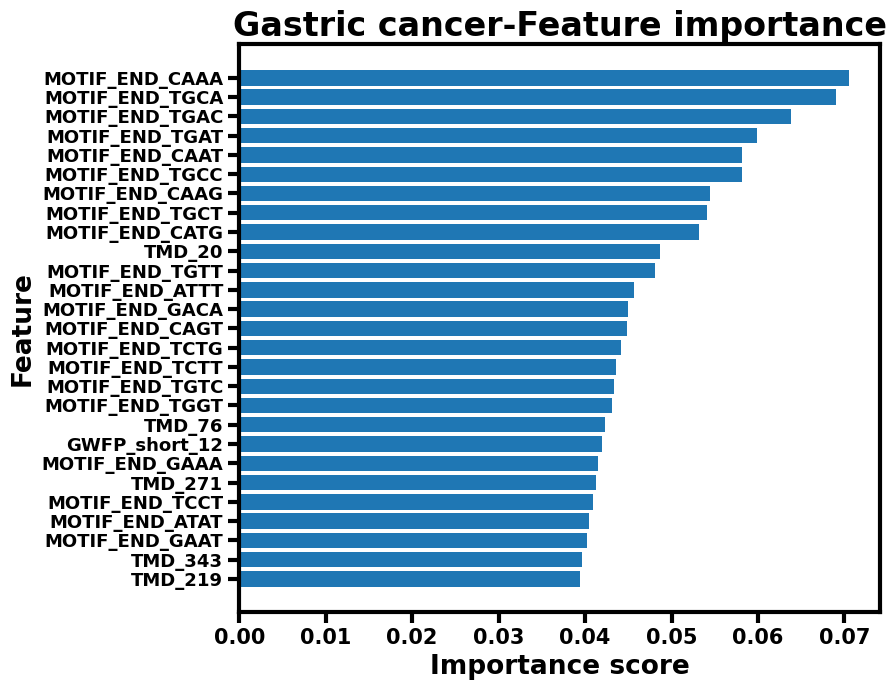

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取数据
file_path = '/home/xwluo/cfDNA/elife/ReliefF/Gastric_feature_importance copy.csv'
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])

# 取前11个特征
df = df.head(27)

# 按值从大到小排序，便于绘图时从上到下展示
df = df.sort_values(by='Value', ascending=True)

# 画图
plt.figure(figsize=(9, 7))
bars = plt.barh(df['Marker'], df['Value'], color='#1f77b4')

# 设置标签字体加粗
plt.xlabel("Importance score", fontsize=19, fontweight='bold')
plt.ylabel("Feature", fontsize=19, fontweight='bold')
plt.title('Gastric cancer-Feature importance', fontsize=24, fontweight='bold')

# 美化坐标轴

plt.grid(False)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')
plt.yticks(fontsize=13, fontweight='bold')
plt.tight_layout()

# 保存图像
plt.savefig("Top_Feature_Barplot_Gastric.png", dpi=300)
plt.show()
